In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ratings = pd.read_csv("../files/ratings.csv")
books   = pd.read_csv("../files/books.csv")

ratings = ratings[ratings["user_id"].isin(ratings["user_id"].unique()[:1000])]


print("Пропуски в ratings:")
print(ratings.isna().sum())
print("\nДубликаты в ratings:")
print(ratings.duplicated().sum())

ratings = ratings.drop_duplicates().dropna()
ratings["user_id"] = ratings["user_id"].astype(int)
ratings["book_id"] = ratings["book_id"].astype(int)
ratings["rating"]  = ratings["rating"].astype(float)

print("Минимальная оценка:", ratings["rating"].min())
print("Максимальная оценка:", ratings["rating"].max())
print("Средняя оценка:", ratings["rating"].mean())

Пропуски в ratings:
user_id    0
book_id    0
rating     0
dtype: int64

Дубликаты в ratings:
0
Минимальная оценка: 1.0
Максимальная оценка: 5.0
Средняя оценка: 3.7560008979761


In [3]:
users = ratings["user_id"].nunique()
items = ratings["book_id"].nunique()
ratings_count = len(ratings)

print("Пользователей:", users)
print("Книг:", items)
print("Оценок:", ratings_count)
print("Среднее число оценок на пользователя:",
      ratings_count / users)

sparsity = 1 - ratings_count / (users * items)
print("Разреженность:", sparsity)

Пользователей: 1000
Книг: 7532
Оценок: 115816
Среднее число оценок на пользователя: 115.816
Разреженность: 0.984623473181094


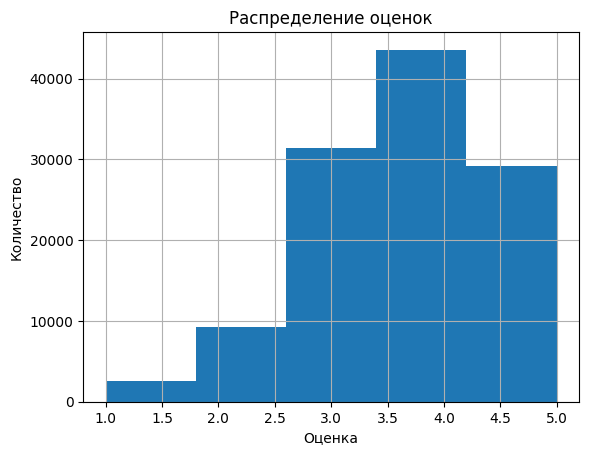

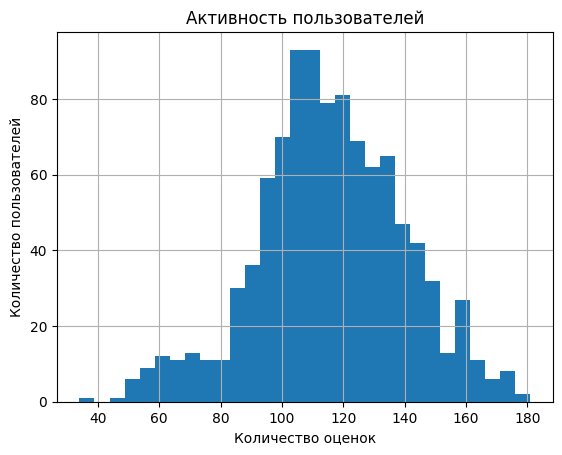

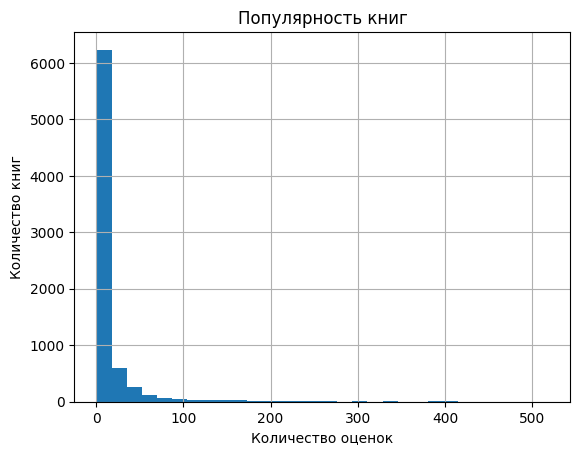

In [4]:
ratings["rating"].hist(bins=5)
plt.xlabel("Оценка"); plt.ylabel("Количество")
plt.title("Распределение оценок")
plt.show()

ratings.groupby("user_id").size().hist(bins=30)
plt.xlabel("Количество оценок"); plt.ylabel("Количество пользователей")
plt.title("Активность пользователей")
plt.show()

ratings.groupby("book_id").size().hist(bins=30)
plt.xlabel("Количество оценок"); plt.ylabel("Количество книг")
plt.title("Популярность книг")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(ratings, test_size=0.2, random_state=42)

users = sorted(ratings["user_id"].unique())
items = sorted(ratings["book_id"].unique())
user_index = {u: i for i, u in enumerate(users)}
item_index = {b: i for i, b in enumerate(items)}

R = np.zeros((len(users), len(items)), dtype=np.float32)
for row in train.itertuples():
    R[user_index[row.user_id], item_index[row.book_id]] = row.rating

user_mean = np.zeros(len(users), dtype=np.float32)
for u in range(len(users)):
    rated = R[u] > 0
    user_mean[u] = R[u, rated].mean() if rated.any() else train["rating"].mean()

R_centered = np.zeros_like(R)
for u in range(len(users)):
    rated = R[u] > 0
    R_centered[u, rated] = R[u, rated] - user_mean[u]

U, S, Vt = np.linalg.svd(R_centered, full_matrices=False)
k = 20
U_k  = U[:, :k]
S_k  = np.diag(S[:k])
Vt_k = Vt[:k, :]

R_pred = U_k @ S_k @ Vt_k + user_mean[:, np.newaxis]
R_pred = np.clip(R_pred, 1.0, 5.0)
print("SVD выполнено, shape:", R_pred.shape)

SVD выполнено, shape: (1000, 7532)


In [6]:
errors = []
for row in test.itertuples():
    u = user_index[row.user_id]
    i = item_index[row.book_id]
    errors.append(row.rating - R_pred[u, i])

rmse = np.sqrt(np.mean(np.array(errors) ** 2))
print("RMSE:", rmse)

RMSE: 0.9238624543486


In [7]:
def recommend_books(user_id, top_n=10):
    u = user_index[user_id]
    watched = set(ratings.loc[ratings["user_id"] == user_id, "book_id"])
    scores = [(item, R_pred[u, item_index[item]])
              for item in item_index if item not in watched]
    scores.sort(key=lambda x: x[1], reverse=True)
    recs = scores[:top_n]
    result = pd.DataFrame(recs, columns=["book_id", "predicted_rating"])
    return result.merge(books[["book_id", "title", "authors"]], on="book_id")

recommend_books(4)

,book_id,predicted_rating,title,authors
0,43,4.289109,Jane Eyre,"Charlotte Brontë, Michael Mason"
1,233,4.111498,Love in the Time of Cholera,"Gabriel García Márquez, Edith Grossman"
2,225,4.107744,East of Eden,John Steinbeck
3,66,4.106238,Gone with the Wind,Margaret Mitchell
4,80,4.057452,The Little Prince,"Antoine de Saint-Exupéry, Richard Howard, Dom ..."
5,92,4.045842,Freakonomics: A Rogue Economist Explores the H...,"Steven D. Levitt, Stephen J. Dubner"
6,89,4.042504,The Princess Bride,William Goldman
7,15,4.039444,The Diary of a Young Girl,"Anne Frank, Eleanor Roosevelt, B.M. Mooyaart-D..."
8,523,4.035352,The Things They Carried,Tim O'Brien
9,658,4.029780,The Corrections,Jonathan Franzen


In [10]:
def build_all_recommendations(user_ids, top_n=10):
    """{user_id: [(book_id, predicted_rating), ...]}"""
    recs = {}
    for user_id in user_ids:
        u = user_index[user_id]
        watched = set(train.loc[train["user_id"] == user_id, "book_id"]) 
        scored = [(b, float(R_pred[u, item_index[b]]))
                  for b in item_index if b not in watched]
        scored.sort(key=lambda x: x[1], reverse=True)
        recs[user_id] = scored[:top_n]
    return recs


eval_users = [u for u in test["user_id"].unique()[:500] if u in user_index]
all_recommendations = build_all_recommendations(eval_users, top_n=10)


def precision_recall(k):
    p_vals, r_vals = [], []
    for user_id in all_recommendations:
        user_test = test[test["user_id"] == user_id]
        relevant = set(user_test[user_test["rating"] >= 4]["book_id"])
        if not relevant:
            continue
        recommended = set(b for b, _ in all_recommendations[user_id][:k])
        correct = len(recommended & relevant)
        p_vals.append(correct / k)
        r_vals.append(correct / len(relevant))
    return float(np.mean(p_vals)), float(np.mean(r_vals))


def coverage(k):
    rec_items = set()
    for uid in all_recommendations:
        for b, _ in all_recommendations[uid][:k]:
            rec_items.add(b)
    return len(rec_items) / len(items)


def novelty(k):
    pop = train.groupby("book_id").size().to_dict()
    N = len(train)
    scores = []
    for uid in all_recommendations:
        for b, _ in all_recommendations[uid][:k]:
            p = pop.get(b, 1) / N
            scores.append(-np.log2(p))
    return float(np.mean(scores))


def ils(k):
    authors = books.set_index("book_id")["authors"].to_dict()
    sims = []
    for uid in all_recommendations:
        recs = [b for b, _ in all_recommendations[uid][:k]]
        for i in range(len(recs)):
            for j in range(i + 1, len(recs)):
                a = set(str(authors.get(recs[i], "")).split(","))
                b = set(str(authors.get(recs[j], "")).split(","))
                sims.append(len(a & b) / max(len(a | b), 1))
    return float(np.mean(sims)) if sims else 0.0


def diversity(k):
    return 1 - ils(k)


def serendipity(k):
    global_mean = train["rating"].mean()
    hits, total = 0, 0
    for uid in all_recommendations:
        u_test = test[(test["user_id"] == uid) &
                      (test["rating"] >= 4)]["book_id"].values
        for b, score in all_recommendations[uid][:k]:
            if b in u_test and score > global_mean:
                hits += 1
            total += 1
    return hits / total if total else 0.0


In [ ]:
def show_top_n(user_id, n):
    """Печатает TOP-n книг для пользователя с названиями и авторами."""
    if user_id not in all_recommendations:
        print(f"Пользователь {user_id} не в eval_users — постройте для него отдельно.")
        return

    recs = all_recommendations[user_id][:n]

    rows = []
    for rank, (book_id, score) in enumerate(recs, 1):
        meta = books.loc[books["book_id"] == book_id]
        title = meta["title"].values[0] if len(meta) else "?"
        author = meta["authors"].values[0] if len(meta) else "?"
        rows.append({
            "rank": rank,
            "book_id": book_id,
            "predicted_rating": round(score, 4),
            "title": title,
            "authors": author,
        })
    return pd.DataFrame(rows)


uid = eval_users[0]
print(f"Пользователь: {uid}\n")

for n in [3, 5, 10]:
    print(f"===== TOP-{n} =====")
    df = show_top_n(uid, n)
    print(df.to_string(index=False))
    print()

Пользователь: 605

===== TOP-3 =====
 rank  book_id  predicted_rating                   title         authors
    1       11            4.3794         The Kite Runner Khaled Hosseini
    2        3            4.0419 Twilight (Twilight, #1) Stephenie Meyer
    3       81            4.0010        The Glass Castle Jeannette Walls

===== TOP-5 =====
 rank  book_id  predicted_rating                   title           authors
    1       11            4.3794         The Kite Runner   Khaled Hosseini
    2        3            4.0419 Twilight (Twilight, #1)   Stephenie Meyer
    3       81            4.0010        The Glass Castle   Jeannette Walls
    4       14            3.9969             Animal Farm     George Orwell
    5       40            3.9494         Eat, Pray, Love Elizabeth Gilbert

===== TOP-10 =====
 rank  book_id  predicted_rating                                   title                                                                        authors
    1       11            4.37

In [ ]:
for k in [3, 5, 10]:
    p, r = precision_recall(k)
    print(f"TOP-{k}: Precision={p:.4f} Recall={r:.4f} "
          f"Coverage={coverage(k):.4f} Novelty={novelty(k):.4f} "
          f"ILS={ils(k):.4f} Diversity={diversity(k):.4f} "
          f"Serendipity={serendipity(k):.4f}")

TOP-3: Precision=0.2207 Recall=0.0402 Coverage=0.0088 Novelty=8.8429 ILS=0.1216 Diversity=0.8784 Serendipity=0.1980
TOP-5: Precision=0.1720 Recall=0.0524 Coverage=0.0106 Novelty=8.9147 ILS=0.0860 Diversity=0.9140 Serendipity=0.1504
TOP-10: Precision=0.1140 Recall=0.0687 Coverage=0.0156 Novelty=9.0415 ILS=0.0475 Diversity=0.9525 Serendipity=0.0940


In [20]:
for k in [10, 20, 50]:
    U_k = U[:, :k]; S_k = np.diag(S[:k]); Vt_k = Vt[:k, :]
    Rk = np.clip(U_k @ S_k @ Vt_k + user_mean[:, np.newaxis], 1.0, 5.0)
    errs = [row.rating - Rk[user_index[row.user_id], item_index[row.book_id]]
            for row in test.itertuples()]
    print(f"k={k}: RMSE={np.sqrt(np.mean(np.array(errs)**2)):.6f}")

k=10: RMSE=0.890913
k=20: RMSE=0.889942
k=50: RMSE=0.890590
